<a href="https://colab.research.google.com/github/sancheznaranjoyairchayanne-design/tecnm-desarrollo-web/blob/main/laboratorios/sesion04/sesion04_laboratorio.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Sesión 04 · Anatomía RESTful, URIs Nombres y Recursos

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** ¿La URL debe describir una acción o un recurso?

---

## 🖥️ Así se verá el resultado final

```http
$ curl "http://127.0.0.1:8000/api/autores/1/libros"
HTTP/1.1 200 OK
{"autor_id":1,"libros":[
  {"id":1,"titulo":"Cien años de soledad","genero":"novela"},
  {"id":2,"titulo":"Doce cuentos peregrinos","genero":"cuento"}
]}

$ curl "http://127.0.0.1:8000/api/autores/1/libros?genero=cuento&limite=1"
HTTP/1.1 200 OK
{"autor_id":1,"libros":[
  {"id":2,"titulo":"Doce cuentos peregrinos","genero":"cuento"}
]}

$ curl "http://127.0.0.1:8000/api/autores/99/libros"
HTTP/1.1 404 Not Found
{"detail":"Autor no encontrado"}
```

_La ruta dice qué recurso; el verbo dice qué hacer. Nunca /obtenerLibros._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Diseñar URIs jerárquicas basadas en sustantivos.
- Elegir entre parámetros de ruta y parámetros de consulta.
- Responder 404 cuando el recurso solicitado no existe.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] Libros del autor 1 → HTTP 200
- [ ] Filtro por género y límite → HTTP 200
- [ ] Un autor inexistente produce 404 → HTTP 404
- [ ] La colección completa de libros → HTTP 200

## 🧩 El reto

Diseña una API de autores y libros donde las rutas nombren recursos, no acciones.

**Requisitos del contrato**

- GET /api/autores/{autor_id}/libros responde 200 con los libros del autor.
- El parámetro opcional `genero` filtra por género y `limite` recorta la lista.
- GET /api/autores/99/libros responde 404 si el autor no existe.
- No incluyas verbos en las rutas: la acción la define el método HTTP.
- Siembra exactamente: autor 1 Gabriel García Márquez con «Cien años de soledad» (novela) y «Doce cuentos peregrinos» (cuento); autor 2 Julio Cortázar con «Rayuela» (novela).

> **Pista conceptual:** Un parámetro de ruta identifica; un parámetro de consulta filtra. Si tu ruta responde «lo mismo pero más pequeño», probablemente es un filtro y va después del signo de interrogación.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion04.md` con tu decisión de diseño de URIs.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [26]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [25]:
%%writefile app.py
from fastapi import FastAPI, HTTPException

app = FastAPI(title="Tu jerarquía de recursos responderá así")

AUTORES = {
    1: {"id": 1, "nombre": "Gabriel García Márquez"},
    2: {"id": 2, "nombre": "Julio Cortázar"}
}

LIBROS = [
    {
        "id": 1,
        "titulo": "Cien años de soledad",
        "genero": "novela",
        "autor_id": 1
    },
    {
        "id": 2,
        "titulo": "Doce cuentos peregrinos",
        "genero": "cuento",
        "autor_id": 1
    },
    {
        "id": 3,
        "titulo": "Rayuela",
        "genero": "novela",
        "autor_id": 2
    }
]

@app.get("/api/autores/{autor_id}/libros")
def obtener_libros(
    autor_id: int,
    genero: str | None = None,
    limite: int | None = None
):
    if autor_id not in AUTORES:
        raise HTTPException(
            status_code=404,
            detail="Autor no encontrado"
        )

    libros = [
        {
            "id": libro["id"],
            "titulo": libro["titulo"],
            "genero": libro["genero"]
        }
        for libro in LIBROS
        if libro["autor_id"] == autor_id
    ]

    if genero:
        libros = [l for l in libros if l["genero"] == genero]

    if limite is not None:
        libros = libros[:limite]

    return {
        "autor_id": autor_id,
        "libros": libros
    }

@app.get("/api/libros")
def listar_libros():
    return {
        "libros": [
            {
                "id": libro["id"],
                "titulo": libro["titulo"],
                "genero": libro["genero"]
            }
            for libro in LIBROS
        ]
    }



Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** | Desarrollo de una API REST con FastAPI en Google Colab. Se debe trabajar con rutas RESTful, parámetros de ruta y consulta, respuestas JSON y códigos HTTP. No se requiere base de datos, los datos pueden almacenarse en memoria. |
| **Rol**|Actúa como desarrollador backend especializado en FastAPI y diseño de APIs RESTful, implementando exactamente el contrato solicitado por el verificador.|
| **Especificación** |Implementar GET /api/autores/{autor_id}/libros para devolver los libros de un autor. El parámetro opcional genero filtra los resultados y limite restringe la cantidad devuelta. Si el autor no existe debe responder 404 con el mensaje "Autor no encontrado". Implementar también GET /api/libros para devolver la colección completa de libros. Los datos sembrados deben incluir: Gabriel García Márquez con Cien años de soledad y Doce cuentos peregrinos; Julio Cortázar con Rayuela. No utilizar verbos en las rutas.|
| **Output** |Archivo app.py funcional en FastAPI que supere los 4 casos del verificador y responda en formato JSON con los códigos HTTP correctos. |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [27]:
from verificar import probar_http

casos = [{'descripcion': 'Libros del autor 1',
  'metodo': 'GET',
  'ruta': '/api/autores/1/libros',
  'estado': 200,
  'json_contiene': {'autor_id': 1,
                    'libros': [{'id': 1, 'titulo': 'Cien años de soledad', 'genero': 'novela'},
                               {'id': 2, 'titulo': 'Doce cuentos peregrinos', 'genero': 'cuento'}]}},
 {'descripcion': 'Filtro por género y límite',
  'metodo': 'GET',
  'ruta': '/api/autores/1/libros?genero=cuento&limite=1',
  'estado': 200,
  'json_contiene': {'autor_id': 1, 'libros': [{'id': 2, 'titulo': 'Doce cuentos peregrinos', 'genero': 'cuento'}]}},
 {'descripcion': 'Un autor inexistente produce 404',
  'metodo': 'GET',
  'ruta': '/api/autores/99/libros',
  'estado': 404},
 {'descripcion': 'La colección completa de libros',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'estado': 200,
  'json_contiene': {'libros': [{'id': 1}, {'id': 2}, {'id': 3}]}}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 4 casos · app.py
✅ 01. Libros del autor 1
✅ 02. Filtro por género y límite
✅ 03. Un autor inexistente produce 404
✅ 04. La colección completa de libros
------------------------------------------------------------------------------
RESULTADO: 4/4 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion04.md` a `auditorias/auditoria_sesion04.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? = Lo que más me costó fue conseguir que el verificador reconociera correctamente las rutas de la API. Al principio pensaba que el problema estaba en la lógica de los endpoints, pero en realidad el archivo app.py no se estaba guardando correctamente en Colab. Esto provocaba que el verificador devolviera errores 404 incluso cuando el código parecía estar bien implementado.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí utilizar estructuras de datos en memoria mediante diccionarios y listas para almacenar los autores y libros. El contrato no exigía una base de datos ni modelos complejos, por lo que elegí una solución simple que permitiera concentrarme en el diseño REST de las rutas y en el manejo correcto de los parámetros de consulta.


   - ¿Qué error detectó la verificación que tú no habías previsto? = verificación detectó que las rutas esperadas no existían realmente para la aplicación que estaba evaluando. No había previsto que el problema fuera el guardado del archivo y no la implementación de la lógica. Gracias a los mensajes del verificador pude identificar que era necesario guardar correctamente el código utilizando %%writefile app.py antes de ejecutar las pruebas.
3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
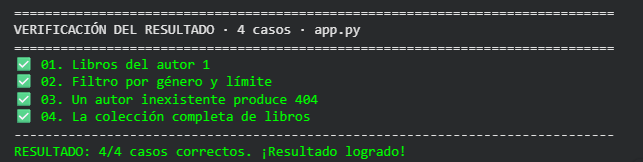
